# Acceptance-rejection method

Lecture 3 (17/11) - Monte Carlo methods

## Exercise

1. Generate $10^6$ points uniformly distributed in $x \in [-1, 1]$ and $y \in [-1, 1]$.
2. Compute the fraction of points falling inside a circle of radius 1.
3. Repeat for $\text{dim} = 2, 3, 4, \dots, 15$.
4. Plot fraction of accepted points as a function of dimension.
5. Assign uncertainty to your estimate of accepted points.
6. Compare (overlay plots) with theoretical expectation of fraction of accepted points.

*Hint from the lecture:* the number of accepted points is binomially distributed.

## Solution

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Functions

In [3]:
# Hypersphere volume formula
def hypersphere_volume(d, r):
    return (math.pi**(d/2) * r**d) / math.gamma(d/2 + 1)

#Hypercube volume formula
def hypercube_volume(d, r):
    return (2*r)**d

### Plots

In [4]:
# Data
N = 10**6
dims = np.arange(2, 16)
rng = np.random.default_rng(12345)

In [5]:
# Monte Carlo: count points inside the unit hypersphere
k = np.empty(len(dims), dtype=np.int64)

for i, d in enumerate(dims):
    # Generate N points in d dimensions
    points = rng.uniform(-1, 1, size=(N, d))
    
    # Count how many points are inside the unit hypersphere
    k[i] = np.sum(np.linalg.norm(points, axis=1) <= 1)

f_mc = k / N
sigma_f = np.sqrt(f_mc * (1 - f_mc) / N)   # binomial standard deviation

# Theory: volume of unit d-ball / volume of cube [-1,1]^d
f_th = np.array([hypersphere_volume(d, 1) / hypercube_volume(d, 1) for d in dims])

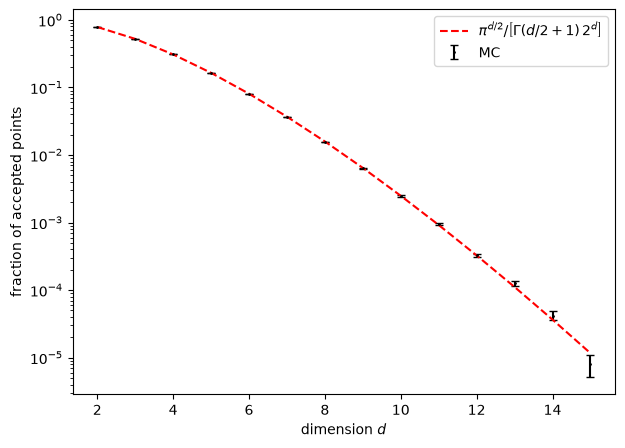

In [7]:
# Plot
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(dims, f_mc, sigma_f, fmt="ko", ms=1, capsize=3, label="MC")
ax.plot(dims, f_th, "r--", label=r"$\pi^{d/2} / \left[\Gamma(d/2+1)\,2^d\right]$")
ax.set_yscale("log")
ax.set_xlabel("dimension $d$")
ax.set_ylabel("fraction of accepted points")
ax.legend()
plt.show()

## Conclusions

- The fraction of accepted points is the ratio between the volume of the unit $d$-ball and that of the cube $[-1,1]^d$, $f(d)=\pi^{d/2}/(\Gamma(d/2+1)\,2^d)$. It decreases from $\pi/4\approx0.785$ at $d=2$ to $\approx1.2\times10^{-5}$ at $d=15$: this is the curse of dimensionality.
- The number of accepted points is binomial, so $\sigma_{\hat f}=\sqrt{\hat f(1-\hat f)/N}$. The absolute uncertainty shrinks with $d$, but the relative one grows from $\sim0.1\%$ at $d=2$ to $\sim30\%$ at $d=15$, where only $\sim12$ of the $10^6$ points are accepted.